# Script to make 2D Plume Height VS Time from NAME Input ESP

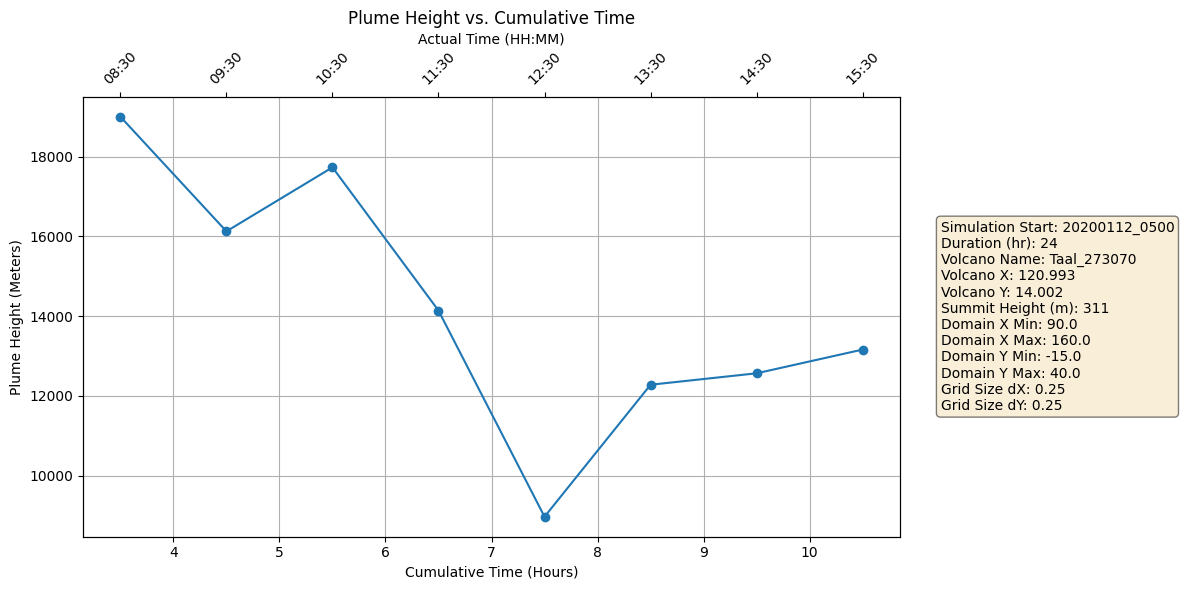

In [3]:
import re
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

class ESP_PlumeDataPlotter:
    def __init__(self, file_path):
        self.file_path = file_path
        self.metadata = {}
        self.emission_data = []
        self.simulation_start = None

    def _parse_metadata(self, lines):
        for line in lines:
            if "simulationStartDatetime" in line:
                value = line.split()[-1].strip()
                self.metadata["Simulation Start"] = value
                self.simulation_start = datetime.strptime(value, "%Y%m%d_%H%M")
            elif "simulationDurationInHour" in line:
                self.metadata["Duration (hr)"] = int(line.split()[-1].strip())
            elif "volcanoName" in line:
                self.metadata["Volcano Name"] = line.split()[-1].strip()
            elif "volcanoX" in line:
                self.metadata["Volcano X"] = float(line.split()[-1].strip())
            elif "volcanoY" in line:
                self.metadata["Volcano Y"] = float(line.split()[-1].strip())
            elif "summitHeightInMetre" in line:
                self.metadata["Summit Height (m)"] = int(line.split()[-1].strip())
            elif "simulationDomain_xMin" in line:
                self.metadata["Domain X Min"] = float(line.split()[-1].strip())
            elif "simulationDomain_xMax" in line:
                self.metadata["Domain X Max"] = float(line.split()[-1].strip())
            elif "simulationDomain_yMin" in line:
                self.metadata["Domain Y Min"] = float(line.split()[-1].strip())
            elif "simulationDomain_yMax" in line:
                self.metadata["Domain Y Max"] = float(line.split()[-1].strip())
            elif "outputGridSize_dX" in line:
                self.metadata["Grid Size dX"] = float(line.split()[-1].strip())
            elif "outputGridSize_dY" in line:
                self.metadata["Grid Size dY"] = float(line.split()[-1].strip())

    def _parse_emission_data(self, lines):
        pattern = re.compile(r"emissionSourceParameterSet_\d+\s+(\d+)_01_00_(\d{4}_\d{2}_\d{2}_\d{2}_\d{2})")
        for line in lines:
            match = pattern.search(line.strip())
            if match:
                height = int(match.group(1))
                timestamp = datetime.strptime(match.group(2), "%Y_%m_%d_%H_%M")
                cumulative_time = (timestamp - self.simulation_start).total_seconds() / 3600
                self.emission_data.append((cumulative_time, height, timestamp.strftime("%H:%M")))

    def load_data(self):
        with open(self.file_path, 'r') as file:
            lines = file.readlines()
        self._parse_metadata(lines)
        self._parse_emission_data(lines)

    def plot(self):
        cumulative_times, heights, actual_times = zip(*self.emission_data)

        fig, ax1 = plt.subplots(figsize=(12, 6))
        ax1.plot(cumulative_times, heights, marker='o')
        ax1.set_xlabel("Cumulative Time (Hours)")
        ax1.set_ylabel("Plume Height (Meters)")
        ax1.set_title("Plume Height vs. Cumulative Time")
        ax1.grid(True)

        # Secondary axis with actual time
        ax2 = ax1.twiny()
        ax2.set_xlim(ax1.get_xlim())
        ax2.set_xticks(cumulative_times)
        ax2.set_xticklabels(actual_times, rotation=45)
        ax2.set_xlabel("Actual Time (HH:MM)")

        # Metadata sidebar
        metadata_text = "\n".join([f"{k}: {v}" for k, v in self.metadata.items()])
        props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
        ax1.text(1.05, 0.5, metadata_text, transform=ax1.transAxes, fontsize=10,
                 verticalalignment='center', bbox=props)

        plt.tight_layout()
        plt.show()

# Create instance and plot
plotter = ESP_PlumeDataPlotter("../Taal_273070_20200112_scenario_infrasound_evolution.txt")
plotter.load_data()
plotter.plot()
